## All imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from factor_analyzer.factor_analyzer import (calculate_bartlett_sphericity)
from factor_analyzer import FactorAnalyzer
from sklearn.preprocessing import LabelEncoder
from scipy.stats import pearsonr

## Reading file

In [2]:
# reading
clean_data = pd.read_csv('advertising_funnel_clean.csv')

## Data preparation

In [3]:
# binary encryption 2 systems
clean_data['os_binary'] = clean_data['os'].map({
    'android': 0,
    'ios': 1
})

In [4]:
clean_data[['os', 'os_binary']].drop_duplicates()

,os,os_binary
0,android,0
2,ios,1


In [5]:
clean_data

,user_id,ad_channel,funnel_stage,price,profit,os,timestamp,actions_count,os_binary
0,991236,native,interest,2.0,NaN,android,150000,1,0
1,335514,banner,interest,0.5,NaN,android,150000,1,0
2,619571,search,consideration,1.5,NaN,ios,150000,1,1
3,387356,search,interest,1.5,NaN,ios,150000,1,1
4,399556,search,interest,1.5,NaN,ios,150000,1,1
...,...,...,...,...,...,...,...,...,...
986696,929180,search,intent,1.5,NaN,ios,224682,1,1
986697,1034498,search,intent,1.5,NaN,ios,225430,1,1
986698,947521,organic_traffic,consideration,0.0,NaN,android,225482,1,0
986699,720354,organic_traffic,purchase,0.0,50.0,android,225495,1,0


In [39]:
# Setting encrypted values by worth
stage_map = {
    'interest': 0,
    'consideration': 1,
    'intent': 2,
    'purchase': 3
}

In [42]:
# filling columns by values
clean_data['funnel_stage_num'] = (
    clean_data['funnel_stage'].map(stage_map)
)
clean_data

,user_id,ad_channel,funnel_stage,price,profit,os,timestamp,actions_count,os_binary,funnel_stage_num,os_factorized,stage_factorized,channel_factorized,ad_channel_encoded
0,991236,native,interest,2.0,NaN,android,150000,1,0,0,0,0,0,1
1,335514,banner,interest,0.5,NaN,android,150000,1,0,0,0,0,1,0
2,619571,search,consideration,1.5,NaN,ios,150000,1,1,1,1,1,2,6
3,387356,search,interest,1.5,NaN,ios,150000,1,1,0,1,0,2,6
4,399556,search,interest,1.5,NaN,ios,150000,1,1,0,1,0,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
986696,929180,search,intent,1.5,NaN,ios,224682,1,1,2,1,2,2,6
986697,1034498,search,intent,1.5,NaN,ios,225430,1,1,2,1,2,2,6
986698,947521,organic_traffic,consideration,0.0,NaN,android,225482,1,0,1,0,1,3,2
986699,720354,organic_traffic,purchase,0.0,50.0,android,225495,1,0,3,0,3,3,2


In [43]:
# encode the values using the factorize method according to applied conditions
clean_data['os_factorized'], os_names = pd.factorize(
    clean_data['os']
)

clean_data['stage_factorized'], stage_names = pd.factorize(
    clean_data['funnel_stage']
)

clean_data['channel_factorized'], channel_names = pd.factorize(
    clean_data['ad_channel']
)

In [10]:
# duplicates cleaning
print(clean_data[['os', 'os_factorized']].drop_duplicates())

        os  os_factorized
0  android              0
2      ios              1


In [11]:
print(
    clean_data[
        ['funnel_stage', 'stage_factorized']
    ].drop_duplicates()
)

     funnel_stage  stage_factorized
0        interest                 0
2   consideration                 1
29         intent                 2
39       purchase                 3


In [12]:
print(
    clean_data[
        ['ad_channel', 'channel_factorized']
    ].drop_duplicates()
)

          ad_channel  channel_factorized
0             native                   0
1             banner                   1
2             search                   2
6    organic_traffic                   3
10             video                   4
39   partner_network                   5
173            other                   6
270             rich                   7


## Correlations

In [44]:
# creating DF to check correlation
corr_df = clean_data[
    [
        'user_id',
        'price',
        'profit',
        'os_binary',
        'funnel_stage_num',
        'channel_factorized'
    ]
]

In [14]:
# correlation counter
corr_matrix = corr_df.corr()
corr_matrix

,user_id,price,profit,os_binary,funnel_stage_num,channel_factorized
user_id,1.000000,0.088062,0.021970,0.054444,0.045437,-0.032156
price,0.088062,1.000000,-0.000043,0.236257,0.014447,-0.118554
profit,0.021970,-0.000043,1.000000,0.002195,NaN,0.097279
os_binary,0.054444,0.236257,0.002195,1.000000,0.013031,-0.034214
funnel_stage_num,0.045437,0.014447,NaN,0.013031,1.000000,-0.043155
channel_factorized,-0.032156,-0.118554,0.097279,-0.034214,-0.043155,1.000000


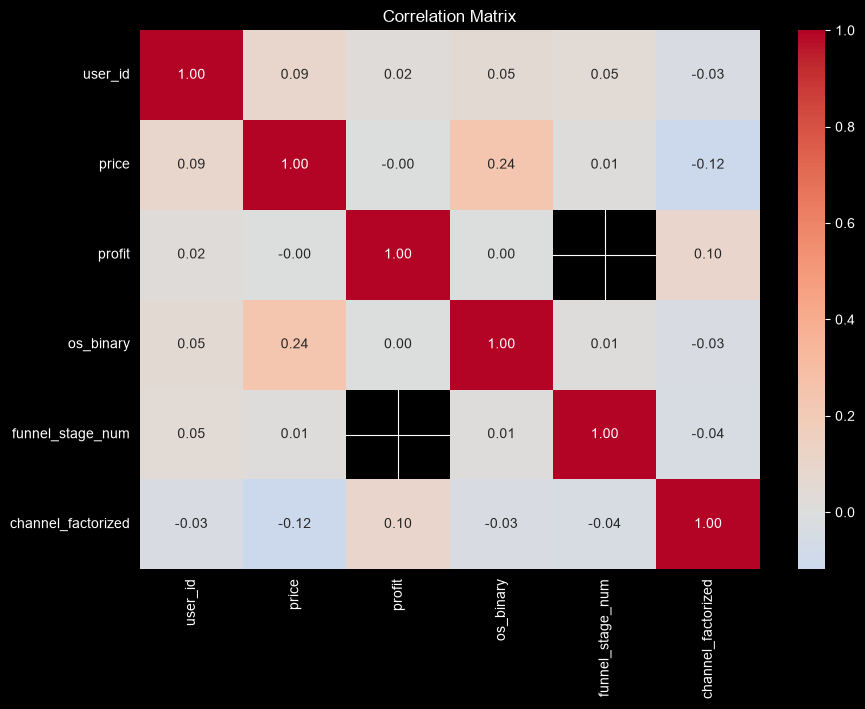

In [45]:
plt.figure(figsize=(10, 7)) # Creating matrix

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [46]:
# filling nan in price column
pearson_data = clean_data[
    ['price', 'user_id']
].dropna()

In [47]:
# Pearson correlation between price and users
pearson_corr, p_value = pearsonr(
    pearson_data['price'],
    pearson_data['user_id']
)

print('Pearson correlation:', pearson_corr)
print('p-value:', p_value)

Pearson correlation: 0.088061890891835
p-value: 0.0


In [18]:
# Using Label Encoder to encode string values from ad channels
le = LabelEncoder()

clean_data['ad_channel_encoded'] = le.fit_transform(
    clean_data['ad_channel']
)

In [48]:
# DF creating and save values
channel_mapping = pd.DataFrame({
    'channel': le.classes_,
    'code': le.transform(le.classes_)
})

channel_mapping

,channel,code
0,banner,0
1,native,1
2,organic_traffic,2
3,other,3
4,partner_network,4
5,rich,5
6,search,6
7,video,7


In [49]:
# DF for factor analysis
fa_data = clean_data[
    [
        'price',
        'profit',
        'os_binary',
        'funnel_stage_num',
        'ad_channel_encoded'
    ]
].copy()

In [21]:
clean_data.groupby('funnel_stage')['profit'].count()

funnel_stage
consideration       0
intent              0
interest            0
purchase         4877
Name: profit, dtype: int64

In [22]:
fa_data['price'] = fa_data['price'].fillna(
    fa_data['price'].median()
) # filling nan values by median

In [50]:
fa_data['profit'] = fa_data['profit'].fillna(0) # equalize unknown values to 0

In [51]:
# check
fa_data.isna().sum()

price                 5304
profit                   0
os_binary                0
funnel_stage_num         0
ad_channel_encoded       0
dtype: int64

In [25]:
factor_data = clean_data[
    [
        'ad_channel',
        'funnel_stage',
        'os',
        'price',
        'profit'
    ]
].copy() # setting data for Bartlett's test

In [26]:
# factorize categorical values
factor_data['ad_channel'] = pd.factorize(
    factor_data['ad_channel']
)[0]

factor_data['funnel_stage'] = pd.factorize(
    factor_data['funnel_stage']
)[0]

factor_data['os'] = pd.factorize(
    factor_data['os']
)[0] 

In [27]:
factor_data['profit'] = factor_data['profit'].fillna(0)

factor_data['price'] = factor_data['price'].fillna(
    factor_data['price'].median()
) # filling nan data

In [52]:
factor_data.info() # here has to be encrypted values in numerical types

<class 'pandas.DataFrame'>
RangeIndex: 986701 entries, 0 to 986700
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   ad_channel    986701 non-null  int64  
 1   funnel_stage  986701 non-null  int64  
 2   os            986701 non-null  int64  
 3   price         986701 non-null  float64
 4   profit        986701 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 37.6 MB


In [55]:
#!pip install factor_analyzer
# install library

#%pip install scikit-learn==1.7.2
#import sklearn
#import factor_analyzer
#from importlib.metadata import version

#print("scikit-learn:", sklearn.__version__)
#print("factor-analyzer:", version("factor-analyzer"))


# if the library has errors use this code to fix it


In [30]:
# Test
chi_square_value, p_value = (
    calculate_bartlett_sphericity(factor_data)
)

print('Chi-square:', chi_square_value)
print('p-value:', p_value)

Chi-square: 113863.85628924168
p-value: 0.0


In [58]:
# Factors setting
fa = FactorAnalyzer(
    rotation=None
)
fa.fit(factor_data)
eigenvalues, vectors = fa.get_eigenvalues()

C:\Users\csmat\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [59]:
eigenvalues # проверка

array([1.2921866 , 1.19224998, 0.97247131, 0.79525215, 0.74783996])

In [ ]:
# Scree plot
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker='o'
)

plt.axhline(
    y=1,
    linestyle='--'
)

plt.xlabel('Factor number')
plt.ylabel('Value')
plt.title('Scree plot')

plt.show()

In [34]:
sum(eigenvalues > 1)

np.int64(2)

In [63]:
# model
fa = FactorAnalyzer(
    n_factors=2, # eigenvalues 2 optimal
    rotation='varimax'
)

fa.fit(factor_data)

C:\Users\csmat\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,2
,rotation,'varimax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [64]:
# Factor load
loadings = pd.DataFrame(
    fa.loadings_,
    index=factor_data.columns,
    columns=['Factor 1', 'Factor 2']
)

loadings

,Factor 1,Factor 2
ad_channel,-0.037802,-0.130257
funnel_stage,0.996747,0.039058
os,0.002945,0.261583
price,-0.020832,0.901034
profit,0.203576,0.018917


In [65]:
loadings.round(3)

,Factor 1,Factor 2
ad_channel,-0.038,-0.130
funnel_stage,0.997,0.039
os,0.003,0.262
price,-0.021,0.901
profit,0.204,0.019


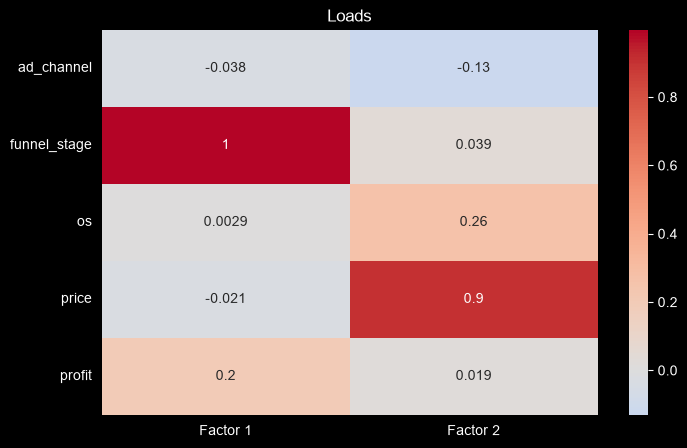

In [67]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Loads')
plt.show()

## Conclusion

The first factor can be interpreted as financial and commercial, since the price has the greatest burden in it, and the advertising channel also shows a noticeable connection.
The second factor reflects the user's passage through the sales funnel, since the maximum factor load falls on the funnel_stage attribute and is 0.968.

Based on the data in the correlation matrix, I can draw several conclusions:

I see a small positive result in the correlation between Price and OS, which indicates a positive trend from iOS users than from Android, because (1= iOS, and 0 =Android)


I see about zero indicators of the funnel stage and price, which indicates that The price of the product is not important to the user and there is no influence on his progress through the funnel.